![Banner](../images/09_03_banner_rs_rader.png)


# Differential InSAR (DInSAR)

This notebook explains differential InSAR (DInSAR), which measures ground displacement from the phase difference of two SAR images taken at different times, walks through the Sentinel-1 processing workflow, and applies it with GeoLattice to the subsidence of Mexico City.


## Overview

DInSAR measures ground displacement from the phase difference between two SAR images of the same area taken at different times. It isolates the part of the interferometric phase caused by surface motion along the radar line of sight (LOS). The precision is a fraction of the radar wavelength, typically centimetres to millimetres.

A SAR pixel is a complex number $s = A e^{i\phi}$. The phase $\phi$ depends on the two-way path length $R$ to the ground:

$$\phi = -\frac{4\pi}{\lambda}R + \phi_{scat}$$

Take two acquisitions, a reference $s_1$ (time $t_1$) and a secondary $s_2$ (time $t_2$). Multiplying one by the complex conjugate of the other gives the interferogram:

$$I = s_1 s_2^* = A_1A_2\, e^{i(\phi_1-\phi_2)}$$

If the scattering properties stay the same between dates, $\phi_{scat}$ cancels. What remains is driven by geometry and by any change in path length.


## Core concepts

### Learning objectives

1. Decompose interferometric phase into flat-Earth, topographic, deformation, atmospheric, orbit and noise terms, and identify the term DInSAR retains.
2. Relate perpendicular baseline to the height of ambiguity for a Sentinel-1 deformation pair.
3. Project 3D displacement onto the line of sight, including how ascending and descending tracks separate vertical and east-west motion.
4. Coregister a Sentinel-1 TOPS stack with back-geocoding and enhanced spectral diversity, then form a differential interferogram.
5. Multilook and Goldstein-filter the Mexico City pair, and unwrap it with SNAPHU in DEFO mode.
6. Convert unwrapped phase to line-of-sight displacement, geocode it, and reference it to a stable point.
7. Remove an orbital ramp and a topography-correlated tropospheric delay, and compare the pair and an SBAS time series with GNSS.

### Contents

1. Phase decomposition
2. DInSAR configurations
3. LOS geometry and 3D motion
4. Main error sources and limitations
5. Beyond single-pair DInSAR: multi-temporal InSAR
6. Applications
7. Python and open tools
8. Sentinel-1 DInSAR Processing Workflow
9. DInSAR with GeoLattice: the subsidence of Mexico City
10. Summary, exercises and references


## Phase decomposition

The interferometric phase is the sum of several contributions:

$$\Delta\phi = \phi_{flat} + \phi_{topo} + \phi_{defo} + \phi_{atm} + \phi_{orb} + \phi_{noise} + 2\pi k$$

| Term | Cause | How it is handled |
|---|---|---|
| $\phi_{flat}$ | Reference ellipsoid ("flat-earth") phase from baseline geometry | Removed using precise orbits |
| $\phi_{topo}$ | Topography seen from slightly different positions | Removed using an external DEM |
| $\phi_{defo}$ | **Ground motion (the signal)** | Retained |
| $\phi_{atm}$ | Differences in tropospheric and ionospheric delay | Filtering, weather models, GACOS, stacking |
| $\phi_{orb}$ | Residual orbit errors, which appear as ramps | Ramp fitting or removal |
| $\phi_{noise}$ | Decorrelation and thermal noise | Multilooking and filtering |
| $2\pi k$ | Phase is only known modulo $2\pi$ | Phase unwrapping |


### Topographic phase

$$\phi_{topo} = -\frac{4\pi}{\lambda}\frac{B_\perp\, h}{R\sin\theta}$$

Here $B_\perp$ is the perpendicular baseline, $h$ is the height, $R$ is the slant range and $\theta$ is the incidence angle. The **height of ambiguity** is the height change that produces one full fringe:

$$h_a = \frac{\lambda R \sin\theta}{2B_\perp}$$

A small $B_\perp$ gives a large $h_a$. The interferogram is then less sensitive to topography and to DEM errors, which suits deformation work. A large $B_\perp$ is better for generating DEMs.


### Deformation phase

$$\phi_{defo} = -\frac{4\pi}{\lambda}\, d_{LOS}$$

Sign conventions vary by software. Many tools report positive values as motion toward the satellite.

One fringe ($2\pi$) corresponds to $\lambda/2$ of LOS motion:

| Sensor / band | λ | Displacement per fringe |
|---|---|---|
| TerraSAR-X, COSMO-SkyMed (X) | ~3.1 cm | ~1.6 cm |
| Sentinel-1, RADARSAT-2 (C) | ~5.55 cm | ~2.8 cm |
| ALOS-2, NISAR (L) | ~23.6 to 24 cm | ~12 cm |

Shorter wavelengths are more sensitive to small motions but lose coherence faster over vegetation. L-band penetrates vegetation better and stays coherent longer.


## DInSAR configurations

- **Two-pass:** two SAR images plus an external DEM (SRTM, Copernicus DEM, etc.) to simulate and remove $\phi_{topo}$. This is the standard approach today.
- **Three-pass:** one image pair with no deformation (a topographic pair) and one pair spanning the deformation. The topo pair is scaled by the ratio of the baselines and subtracted.
- **Four-pass:** the same idea using two independent pairs.


## LOS geometry and 3D motion

DInSAR measures only the projection of the 3D displacement vector onto the LOS unit vector:

$$d_{LOS} = \mathbf{d}\cdot\hat{\mathbf{e}}_{LOS} = d_E e_E + d_N e_N + d_U e_U$$

- Sensitivity is highest to vertical and east-west motion.
- Near-polar orbits are almost blind to north-south motion.
- Combining ascending and descending tracks lets you solve for vertical and east-west components.
- Azimuth motion can be recovered with Multiple Aperture InSAR (MAI) or pixel offset tracking. Offset tracking also handles large displacements that exceed what unwrapping can resolve.


## Main error sources and limitations

- **Atmospheric delay:** tropospheric water vapour can introduce several centimetres of apparent motion. It is often correlated with topography and is the biggest limitation for single interferograms.
- **Ionosphere:** significant at L-band. It is corrected with split-spectrum methods.
- **Decorrelation:** vegetation, snow, agriculture, long time spans and large baselines all reduce coherence.
- **DEM errors:** these leak into the deformation phase in proportion to $B_\perp$.
- **Unwrapping errors:** whole-fringe jumps that propagate spatially.
- **Geometric distortions:** layover, foreshortening and shadow in steep terrain.
- **Maximum detectable gradient:** at most about half a fringe per pixel between neighbouring pixels.


## Beyond single-pair DInSAR: multi-temporal InSAR

Single-pair DInSAR is good for large, sudden events such as earthquakes and volcanic inflation. For slow motion, time-series methods average down atmosphere and noise:

- **PSInSAR (Persistent Scatterers):** uses stable point targets like buildings and rocks, all paired with a single reference image. It reaches mm/yr precision in urban areas.
- **SBAS (Small Baseline Subset):** uses many small-baseline interferograms and inverts them for a displacement time series. It works better over distributed scatterers.
- **Hybrid and DS methods:** SqueeSAR, phase linking and EMI combine both approaches.


## Applications

- Earthquake coseismic and postseismic deformation, and fault creep
- Volcanic inflation and deflation
- Land subsidence from groundwater pumping, mining, or oil and gas extraction
- Landslide monitoring
- Monitoring of infrastructure such as dams, bridges and tunnels
- Glacier flow and permafrost
- Agricultural and soil moisture effects, though these often appear as a nuisance in the phase


## Python and open tools

- **ISCE2 / ISCE3:** JPL processing, including topsStack for Sentinel-1
- **SNAP (esa_snappy):** GUI and Python processing graphs
- **GMTSAR / PyGMTSAR:** Sentinel-1 processing that runs from notebooks
- **ASF HyP3:** on-demand cloud-processed Sentinel-1 interferograms, with Python SDK `hyp3_sdk`
- **MintPy:** SBAS time series from ISCE, HyP3 or GMTSAR stacks
- **LiCSBAS:** time series from COMET LiCSAR products
- **SNAPHU:** phase unwrapping, wrapped by `snaphu-py`

A practical pipeline for teaching is HyP3 for interferograms, followed by MintPy for time series and `rasterio`/`xarray` for analysis. It avoids local SAR focusing and coregistration while still showing every phase component.


## Sentinel-1 DInSAR Processing Workflow

Sentinel-1 DInSAR is usually done with **Interferometric Wide (IW) swath SLC** data acquired in **TOPS** mode (Terrain Observation with Progressive Scans). TOPS changes some processing steps compared with stripmap SAR, especially coregistration, so the workflow below follows the Sentinel-1-specific chain as implemented in ESA SNAP. The same logic applies in ISCE2 and GMTSAR.


### Understand the data structure

| Property | Sentinel-1 IW SLC |
|---|---|
| Band / wavelength | C-band, λ ≈ 5.55 cm (≈ 2.8 cm LOS per fringe) |
| Swath | ~250 km, split into 3 sub-swaths (IW1, IW2, IW3) |
| Bursts | Each sub-swath has ~9 to 10 bursts per scene (~20 km azimuth each) |
| Resolution | ~2.3 m (slant range) × ~14 m (azimuth) per look |
| Polarization | VV+VH or HH+HV. **VV is normally used** for InSAR |
| Repeat cycle | 12 days per satellite; 6 days when two satellites are operating |
| Orbit control | Tight orbital tube, so $B_\perp$ is usually small (<200 m) |

TOPS steers the antenna in azimuth during acquisition. This creates a strong Doppler centroid variation within each burst, which is why very precise azimuth coregistration (ESD, Step 6) is required.


### Select the image pair

- **Same relative orbit (track)** and **same orbit direction** (ascending or descending)
- **Same burst coverage**: check burst IDs, since frame boundaries can shift between dates
- **Same polarization** (VV)
- **Short temporal baseline** (6 to 24 days) to keep coherence, unless the event demands a longer span
- **Small perpendicular baseline**: usually fine for Sentinel-1
- For an event (earthquake, eruption), pick one pre-event and one post-event image as close to the event as possible
- Avoid snow cover, heavy rain, or vegetation growth peaks between dates

**Data sources:** ASF Vertex / `asf_search` (Python), Copernicus Data Space Ecosystem.


### Get orbits and DEM

- **Precise orbits (POEORB):** available ~20 days after acquisition, with ~5 cm accuracy. Use these whenever possible.
- **Restituted orbits (RESORB):** available within hours, less accurate. Use only for rapid response.
- **DEM:** Copernicus GLO-30 is the current standard. SRTM 1-arcsec is an alternative within ±60° latitude. SNAP can download either automatically.


### TOPS Split

Read both SLCs and extract only what you need:

- One **sub-swath** (IW1, IW2 or IW3)
- The relevant **burst range**
- The **VV** polarization

This cuts processing time and memory greatly. Process each needed sub-swath separately and merge them later (Step 9).


### Apply orbit file

Replace the orbit state vectors annotated in the metadata with the precise orbit. This improves the geometry used for coregistration, flat-earth removal, topographic phase simulation and geocoding.


### Back-geocoding (DEM-assisted coregistration)

The secondary image is resampled onto the reference geometry:

1. Each reference pixel is projected to ground coordinates using the DEM and the reference orbit.
2. Those ground points are projected back into the secondary image geometry using the secondary orbit.
3. The secondary SLC is resampled to the reference grid. Bicubic or 6-point sinc interpolation is used, with **deramping/reramping** to handle the TOPS azimuth phase ramp.

This purely geometric method gives ~0.01 to 0.05 pixel accuracy. Interferometry needs better than that in azimuth for TOPS.


### Enhanced Spectral Diversity (ESD)

Adjacent bursts overlap by a small amount in azimuth. In these overlap areas, the same ground is seen with **two very different Doppler centroids**. A residual azimuth misregistration $\Delta t$ causes a phase difference between the two views:

$$\Delta\phi_{ovl} = 2\pi\,\Delta f_{DC}^{ovl}\,\Delta t$$

Because $\Delta f_{DC}^{ovl}$ is large (~4 to 5 kHz), even a tiny $\Delta t$ produces a measurable phase. ESD estimates this shift and corrects it to ~0.001 pixel accuracy.

**Why it matters:** without ESD, a misregistration of just 0.01 pixel produces visible **phase jumps at burst boundaries**. These appear as discontinuous stripes in the interferogram.


### Interferogram formation and coherence

For each pixel:

$$I = s_{ref}\, s_{sec}^*$$

During this step:

- **Flat-earth phase** is removed, using the reference ellipsoid and the orbits.
- **Coherence** γ is estimated in a moving window, typically 10×3 (range × azimuth) for IW:
  $$\gamma = \frac{\left|\sum s_1 s_2^*\right|}{\sqrt{\sum|s_1|^2 \sum|s_2|^2}}$$

In SNAP, you can also remove the topographic phase here by enabling **"Subtract topographic phase."**


### TOPS Deburst

Each sub-swath consists of separate bursts with dark gaps and overlaps between them. Deburst stitches the bursts into one continuous image by keeping the valid lines from each burst and discarding redundant overlap lines.


### TOPS Merge (if several sub-swaths)

Join IW1, IW2 and IW3 into one image across the full swath. Each sub-swath must be processed with the same parameters up to this point.


### Topographic phase removal

If you did not already remove it in Step 7, simulate the topographic phase using the DEM, orbits and baseline, then subtract it:

$$\phi_{diff} = \phi_{int} - \phi_{topo}^{sim}$$

The result is the **differential interferogram**. It contains deformation, atmosphere, residual orbit error, DEM error and noise.

Because Sentinel-1 baselines are small, the height of ambiguity is large (often >100 m). DEM errors therefore have little effect on the phase.


### Multilooking

Average complex pixels to reduce noise and produce roughly square ground pixels:

| Looks (range × azimuth) | Approx. ground pixel | Use |
|---|---|---|
| 4 × 1 | ~14 × 14 m | Local, detailed studies |
| 8 × 2 | ~28 × 28 m | General use |
| 20 × 5 | ~70 × 70 m | Regional studies, low-coherence areas, faster unwrapping |

More looks give less noise and easier unwrapping, at the cost of lower spatial resolution.


### Goldstein phase filtering

Adaptive filtering in the frequency domain using patch-wise FFTs:

$$Z(u,v)_{filt} = |Z(u,v)|^{\alpha}\, Z(u,v)$$

- **α** ranges from 0 to 1. The commonly used default is 1.0. Higher values give stronger filtering.
- Typical settings are a 64-pixel FFT window, 3-pixel smoothing, and coherence-based weighting.

Filtering makes fringes clearer and improves unwrapping. It can also oversmooth sharp deformation gradients near faults, so don't overdo it.


### Phase unwrapping

The wrapped phase $(-\pi, \pi]$ is converted to continuous phase by adding the correct integer multiple of $2\pi$:

$$\phi_{unw} = \phi_{wrap} + 2\pi k$$

**SNAPHU** is the standard tool. It uses a statistical cost-flow algorithm. In SNAP the workflow is:

1. **SNAPHU Export:** writes the phase, coherence and a configuration file. Use the `DEFO` mode for deformation and `TOPO` for topography.
2. **Run SNAPHU** externally or through the SNAP plugin. Tiling is often needed for large scenes.
3. **SNAPHU Import:** reads the unwrapped phase back into the product.

Practical tips:

- Mask low-coherence pixels (γ < 0.2 to 0.3) before or after unwrapping.
- Water bodies and dense vegetation cause unwrapping errors.
- For large deformation (e.g., big earthquakes with very dense fringes near the rupture), unwrapping may fail. Offset tracking is the alternative there.


### Phase to displacement

$$d_{LOS} = -\frac{\lambda}{4\pi}\,\phi_{unw}$$

With λ = 0.0555 m, 1 radian of unwrapped phase equals about 4.4 mm of LOS displacement.

**Choose a reference point** in a stable area with high coherence and set its displacement to zero. All values are relative to that point.


### Corrections (optional but recommended)

| Error | Correction approach |
|---|---|
| **Orbital ramp** | Fit and remove a linear or quadratic plane, excluding the deforming area |
| **Tropospheric delay** | GACOS, ERA5 (e.g., via PyAPS), or empirical phase-elevation regression |
| **Ionosphere** | Usually small at C-band. Range split-spectrum can correct it in polar or equatorial regions and for long tracks |
| **Solid earth tides** | Remove using a tide model for large-area, high-precision work |

For a single interferogram, atmospheric noise of 1 to 3 cm is common. This is often the main limit on precision.


### Terrain correction (geocoding)

Convert from radar (slant range / azimuth) geometry to map coordinates using **Range-Doppler Terrain Correction**:

- Uses the same DEM and precise orbits
- Output in WGS84 or UTM, at 10 to 30 m pixel spacing depending on multilooking
- Also geocode the coherence and the LOS incidence angle, which you need for interpretation and decomposition

Export as GeoTIFF for GIS or Python analysis.


### Interpretation and quality control

- Check **coherence maps**. Ignore displacement where γ is low.
- Look for **burst boundary jumps** (an ESD failure) and **unwrapping errors** (sudden 2.8 cm jumps).
- Compare with **GNSS stations** where available.
- Remember that values are **LOS only**. Combine ascending and descending tracks to solve for vertical and east-west components:

$$\begin{bmatrix} d_{LOS}^{asc} \\ d_{LOS}^{desc} \end{bmatrix} = \begin{bmatrix} e_U^{asc} & e_E^{asc} \\ e_U^{desc} & e_E^{desc} \end{bmatrix} \begin{bmatrix} d_U \\ d_E \end{bmatrix}$$


### DInSAR

| Step | SNAP | ISCE2 (topsApp) | GMTSAR |
|---|---|---|---|
| Coregistration | Back-Geocoding | `geo2rdr`, `resamp` | `align_tops.csh` |
| ESD | Enhanced-Spectral-Diversity | `fineoffsets` with ESD | built in |
| Interferogram | Interferogram | `burstifg` | `intf_tops.csh` |
| Filtering | Goldstein | `filter` | `phasefilt` |
| Unwrapping | SNAPHU | `unwrap` (SNAPHU or icu) | `snaphu` |
| Geocoding | Terrain-Correction | `geocode` | `proj_ra2ll.csh` |

**ASF HyP3** runs a GAMMA-based version of this whole chain in the cloud. You submit a pair through `hyp3_sdk` and receive geocoded unwrapped phase, LOS displacement, coherence and incidence angle rasters. This is a convenient way to get analysis-ready interferograms without running steps 3 to 16 yourself.


## DInSAR with GeoLattice: the subsidence of Mexico City

Mexico City is built on the clay of former Lake Texcoco. Pumping groundwater from the aquifer
beneath it compacts the clay, and parts of the city sink by **tens of centimetres per year**,
among the fastest urban subsidence anywhere. That makes it an ideal real-data test for the chain
above: the signal is large, cities stay coherent between acquisitions, and continuous GNSS
stations in the city measure the same motion independently.

This section runs the Sentinel-1 workflow of Steps 1 to 17 natively in Python with `geolattice.rsense`,
first for **one interferogram** (7 January → 13 April 2025), then for a **12-date time series**
through 2025 (the multi-temporal approach above, as an SBAS network), and compares both with
GNSS.

| Step | GeoLattice |
|---|---|
| 1 Pair selection | `asf_search` baseline stack |
| 2 Orbits and DEM | `sar.download_orbit`, `sar.crop_orbit`; Copernicus GLO-30 with `insar.geoid_to_ellipsoid` |
| 3 TOPS Split | `rs.access.asf_download`, `sar.read_slc_annotation`, `sar.burst_window`, `sar.read_slc_burst` |
| 4 Apply orbit file | `sar.apply_orbit_file` |
| 5 to 6 Back-geocoding and ESD, for every date at once | `sar.coregister_stack` (wraps `back_geocode`, `resample_slc`, `esd_azimuth_shift`) |
| 7 and 10 Interferogram, flat-Earth and topographic phase | `insar.topographic_phase`, `insar.differential_interferogram` |
| 8 Deburst (9 Merge: not needed, one sub-swath) | `sar.deburst` |
| 11 to 13 Multilook, Goldstein, SNAPHU | `insar.multilook_complex`, `insar.goldstein_filter`, `insar.unwrap(method="snaphu", cost="defo")` |
| 14 Phase to displacement, reference point | `insar.phase_to_los`, `insar.select_reference_point`, `insar.reference_to_point` |
| 15 Corrections | `insar.remove_ramp` and a phase-elevation fit |
| 16 Terrain correction | `sar.terrain_correct` |
| 17 QC against GNSS | `sar.los_unit_vector`, `insar.enu_to_los` |
| Time series | `insar.sbas_inversion`, `insar.velocity` |

### Data

| Data | Source |
|---|---|
| Sentinel-1 IW SLC bursts, VV, relative orbit 41 (descending), sub-swath IW1, bursts 086877 to 086878, 12 dates in 2025 | ASF burst extractor (NASA Earthdata login in `~/.netrc`) |
| Precise orbits (POEORB) | AWS open data `s1-orbits` |
| Copernicus DEM GLO-30 | Planetary Computer `cop-dem-glo-30` |
| GNSS daily positions (IGS20), stations MMX1 and ICMX | Nevada Geodetic Laboratory (open) |

The 24 bursts are about 3 GB to download; only the AOI window of each is kept, as 16-bit
integers in `Data/08_remote_sensing/08_03_radar/dinsar_mexico_city/` (about 0.9 GB). Later runs reuse the cache.


### Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup for the Mexico City example: libraries, cache folders, the area of interest,
# the twelve 2025 dates, the single pair walked through below, and the two GNSS stations.

import warnings
warnings.filterwarnings("ignore")  # hide library warnings

import io  # in-memory text buffers
import time  # timing
import urllib.request  # download GNSS files over HTTP
from pathlib import Path  # file paths

import asf_search as asf  # ASF search and download
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor on xarray)
import xarray as xr  # labelled rasters
from pyproj import Transformer  # coordinate transformations

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import insar, sar  # InSAR and SAR processing modules

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
CACHE = Path("../../../../Data/08_remote_sensing/08_03_radar/dinsar_mexico_city")       # bursts, orbits, DEM and GNSS files, reused on later runs
OUT = Path("outputs/dinsar_mexico_city")      # geocoded velocity and the displacement time series
for d in (CACHE, OUT):  # create the cache and output folders
    d.mkdir(parents=True, exist_ok=True)  # parents=True also creates missing parent folders

AOI = (-99.24, 19.34, -99.02, 19.50)      # lon/lat: western hills to the old lake bed by the airport
UTM = "EPSG:32614"                        # WGS84 / UTM zone 14N, the map grid of Step 16
POL = "VV"                                # co-polar channel; it stays coherent longer than VH over the city
BURSTS = ["041_086877_IW1", "041_086878_IW1"]   # relative orbit 41, descending; two bursts so ESD has an overlap
# the 12 acquisition dates of the stack
DATES = ["2025-01-07", "2025-02-12", "2025-03-08", "2025-04-13", "2025-05-25", "2025-06-06",
         "2025-07-24", "2025-08-17", "2025-09-22", "2025-10-22", "2025-11-21", "2025-12-15"]
REF = DATES[0]                            # stack reference: every other date is resampled onto 7 January
PAIR = ("2025-01-07", "2025-04-13")       # the single interferogram of Steps 7-17 (96 days)
LOOKS = (2, 8)                            # azimuth x range looks: about 28 m x 34 m on the ground
STATIONS = {"MMX1": (-99.0684, 19.4317), "ICMX": (-99.1709, 19.4056)}   # NGL GNSS stations (lon, lat)
# version, number of dates and the single pair
print(f"geolattice.rsense {rs.__version__} | {len(DATES)} dates | single pair {PAIR[0]} → {PAIR[1]}")

# ASF searches are cached as small JSON files beside the bursts, so later runs need no network.
import json  # read and write the cached search results
from types import SimpleNamespace  # stand-in for an ASF product read back from the cache


def asf_cached(name, stack=False, **query):
    """ASF search results as objects with .properties and .geometry, cached under CACHE / name.

    The first run searches ASF online and saves the properties and footprint of every result.
    Later runs read that file instead. stack=True keeps the baseline stack of the first result.
    """
    path = CACHE / name  # the cached search
    if path.exists():  # searched before: read the local file
        rows = json.loads(path.read_text())
    else:  # first run: search ASF online and save the result
        res = asf.search(**query)  # the search itself
        rows = [{"properties": p.properties, "geometry": p.geometry}  # results or their stack
                for p in (res[0].stack() if stack else res)]
        path.write_text(json.dumps(rows, default=str))  # keep it for the next run
    return [SimpleNamespace(**r) for r in rows]  # objects with .properties and .geometry, like ASF products


geolattice.rsense 0.3.49 | 12 dates | single pair 2025-01-07 → 2025-04-13


### Select the image pair (and the dates of the time series)

Relative orbit 41 is a descending track over central Mexico; on every pass, burst 086877 of
sub-swath IW1 contains both GNSS stations, and the next burst, 086878, overlaps it (two bursts
are needed for ESD). In 2025, Sentinel-1A and the newly launched Sentinel-1C together give an
acquisition every 6 days. We take roughly one date a month with a **small perpendicular
baseline**, as Step 1 recommends: small B⊥ keeps the height of ambiguity large, so DEM errors
hardly leak into the deformation phase.


48 acquisitions of burst 041_086877_IW1 in 2025 ({'S1A': 27, 'S1C': 21}); chosen 12, B⊥ relative to 2025-01-07 between -39 and 32 m


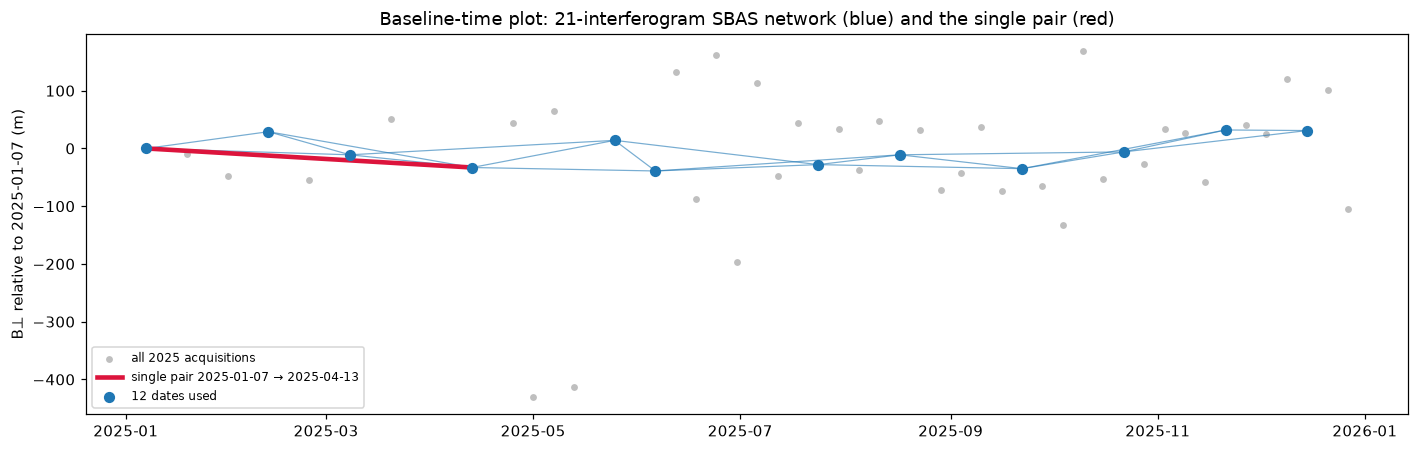

In [2]:
# Step 1. Choose the dates. stack() on one burst lists every acquisition of that same burst
# and the perpendicular baseline of each one relative to the burst we searched for.

# 1. The reference product is the 7 January acquisition of burst 086877.
first_stack = asf_cached("asf_stack_2025.json", stack=True, platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST",
                         fullBurstID=BURSTS[0], polarization=POL, start=REF,
                         end=str(pd.Timestamp(REF) + pd.Timedelta(days=1)))

# 2. One row per acquisition in the stack: date, satellite (the last character of the platform
#    name is A, B, C or D) and B⊥ in metres, relative to 7 January.
stack = pd.DataFrame([{"date": pd.Timestamp(p.properties["startTime"]).tz_convert(None).normalize(),
                       "platform": "S1" + p.properties["platform"][-1], "bperp": p.properties["perpendicularBaseline"]}
                      for p in first_stack]).dropna().sort_values("date")

# 3. Keep 2025, then the twelve dates used below. A small B⊥ is what deformation work wants:
#    it makes the height of ambiguity large, so a DEM error barely leaks into the phase.
year = stack[stack.date.dt.year == 2025].reset_index(drop=True)
# the acquisitions used in this notebook
chosen = year[year.date.dt.strftime("%Y-%m-%d").isin(DATES)].set_index("date")
# number of 2025 acquisitions per platform
print(f"{len(year)} acquisitions of burst {BURSTS[0]} in 2025 ({year.platform.value_counts().to_dict()}); "
      f"chosen {len(chosen)}, B⊥ relative to {REF} between {chosen.bperp.min():.0f} and {chosen.bperp.max():.0f} m")

# 4. SBAS network: each date paired with the next one and the one after that.
#    Twelve dates give 11 + 10 = 21 interferograms, all with a short time gap.
NETWORK = [(DATES[i], DATES[j]) for i in range(len(DATES)) for j in (i + 1, i + 2) if j < len(DATES)]

# 5. Baseline-time plot. Grey points are every 2025 acquisition, thin blue segments are the
#    SBAS pairs, and the thick red segment is the single pair followed in Steps 7-17.
fig, ax = plt.subplots(figsize=(13, 4.2))
# every 2025 acquisition in grey
ax.scatter(year.date, year.bperp, s=12, color="0.75", label="all 2025 acquisitions")
for a, b in NETWORK:  # each interferogram of the SBAS network
    # a blue line between its two dates
    ax.plot([pd.Timestamp(a), pd.Timestamp(b)], [chosen.bperp[pd.Timestamp(a)], chosen.bperp[pd.Timestamp(b)]],
            color="tab:blue", lw=0.8, alpha=0.6)
# the single DInSAR pair in red
ax.plot([pd.Timestamp(d) for d in PAIR], [chosen.bperp[pd.Timestamp(d)] for d in PAIR], color="crimson", lw=3,
        label=f"single pair {PAIR[0]} → {PAIR[1]}")
# the dates used, in blue
ax.scatter(chosen.index, chosen.bperp, s=40, color="tab:blue", zorder=3, label=f"{len(DATES)} dates used")
# labels and title
ax.set(ylabel=f"B⊥ relative to {REF} (m)", title=f"Baseline-time plot: {len(NETWORK)}-interferogram SBAS network (blue) and the single pair (red)")
ax.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()  # legend, arrange and draw

### Orbits, DEM, TOPS Split and Apply Orbit File

`sar.download_orbit` fetches each date's POEORB file from the open AWS `s1-orbits` bucket;
the DEM is Copernicus GLO-30, converted from EGM2008 geoid heights to WGS84 ellipsoidal heights
(orbits and range-Doppler geometry live on the ellipsoid).
TOPS Split downloads only the two bursts per date from ASF's burst extractor and keeps the range
samples covering the AOI.


In [3]:
# Steps 2 and the DEM. Precise orbits replace the state vectors stored in the product.
# The DEM is used only for geometry: back-geocoding, and later the simulated topographic phase.

# 1. Both bursts on each chosen date. The search window is one day past the last date so that
#    date is included; the list comprehension then drops any extra burst that is not in DATES.
found = asf_cached("asf_bursts_2025.json", platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST",
                   fullBurstID=BURSTS, polarization=POL, start=DATES[0],
                   end=str(pd.Timestamp(DATES[-1]) + pd.Timedelta(days=1)))
res_all = [p for p in found if p.properties["startTime"][:10] in DATES]  # keep the chosen dates
# one row per burst: date, burst ID, platform, start time and size
acq = pd.DataFrame([{"date": p.properties["startTime"][:10], "burst": p.properties["burst"]["fullBurstID"],
                     "platform": p.properties["platform"], "start": pd.Timestamp(p.properties["startTime"]).tz_convert(None),
                     "MB": float(p.properties["bytes"]) / 1e6} for p in res_all])

# 2. One POEORB file per date (it covers both bursts of that pass), from the open AWS bucket.
#    crop_orbit keeps the minutes around the acquisition; the 6 s margin covers the burst length.
eof = {d: sar.download_orbit(g.platform.iloc[0], g.start.min(), CACHE / "orbits") for d, g in acq.groupby("date")}
# precise orbit of each date, cropped to the bursts' time span
orbits = {d: sar.crop_orbit(eof[d], g.start.min(), g.start.max() + pd.Timedelta(seconds=6)) for d, g in acq.groupby("date")}

# 3. Copernicus GLO-30 over a box 0.05° larger than the AOI, so the edges still have elevation.
#    The STAC heights are above the EGM2008 geoid. Orbits and the range-Doppler equations live
#    on the WGS84 ellipsoid, so geoid_to_ellipsoid adds the geoid undulation before they are used.
dem_file = CACHE / "copdem30_geoid.tif"
if not dem_file.exists():  # download the DEM once
    import planetary_computer as pc  # Planetary Computer URL signing
    import pystac_client  # STAC search client
    from rioxarray.merge import merge_arrays  # mosaic several rasters

    # open the Planetary Computer STAC catalogue
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)
    box = (AOI[0] - 0.05, AOI[1] - 0.05, AOI[2] + 0.05, AOI[3] + 0.05)  # the AOI plus a 0.05 degree margin
    # Copernicus DEM tiles clipped to that box
    tiles = [rioxarray.open_rasterio(i.assets["data"].href).squeeze("band", drop=True).rio.clip_box(*box)
             for i in cat.search(collections=["cop-dem-glo-30"], bbox=box).items()]
    merge_arrays(tiles).astype("float32").rio.to_raster(dem_file)  # mosaic and save
dem_geoid = rioxarray.open_rasterio(dem_file).squeeze(drop=True)  # the DEM (heights above the EGM2008 geoid)
ell_file = CACHE / "copdem30_ellipsoid.tif"  # the same DEM above the WGS 84 ellipsoid, saved by an earlier run
if ell_file.exists():  # converted before: read it from the local drive
    dem_ell = rioxarray.open_rasterio(ell_file).squeeze(drop=True)
else:  # first run: add the EGM2008 geoid undulation (PROJ reads the geoid grid online) and save it
    dem_ell = insar.geoid_to_ellipsoid(dem_geoid, "EGM2008")
    dem_ell.rio.to_raster(ell_file)  # keep it for the next run
# number of orbit files and elevation range
print(f"{len(eof)} precise orbit files; Copernicus DEM {float(dem_geoid.min()):.0f}-{float(dem_geoid.max()):.0f} m, "
      f"geoid undulation {dem_ell.attrs['geoid_undulation_mean']:.1f} m")

12 precise orbit files; Copernicus DEM 2216-3430 m, geoid undulation -5.4 m


In [4]:
# Steps 3 and 4. TOPS Split keeps two bursts and the range samples over the AOI.
# Apply Orbit File then swaps the precise orbit into each burst's annotation.

SLC = CACHE / "slc"
SLC.mkdir(exist_ok=True)  # create it if needed


def fetch_bursts(date):  # download and crop the bursts of one date (skipped when cached)
    # Download one date, crop each burst to the AOI, and cache it. A later run finds the .npy files and returns.
    if all((SLC / f"{date}_{b}.npy").exists() for b in BURSTS):
        return
    # a. The two burst products for this date, downloaded as GeoTIFF + annotation XML.
    res = asf.search(platform=asf.PLATFORM.SENTINEL1, processingLevel="BURST", fullBurstID=BURSTS,
                     polarization=POL, start=date, end=str(pd.Timestamp(date) + pd.Timedelta(days=1)))
    raw = CACHE / "raw"  # folder for the raw downloads
    raw.mkdir(exist_ok=True)  # create it if needed
    rs.access.asf_download(res, raw)  # download the bursts of this date from ASF
    for p in res:  # each burst
        bid, name = p.properties["burst"]["fullBurstID"], p.properties["fileID"]  # burst ID and file name
        # the image and its annotation XML
        tif, xml = next(raw.glob(f"{name}*.tif*")), next(raw.glob(f"{name}*.xml"))
        # b. The annotation holds timing, Doppler polynomials, the orbit and the geolocation grid.
        #    swath is the last three characters of the burst id ("IW1").
        a = sar.read_slc_annotation(xml, swath=bid[-3:], polarisation=POL)
        i = p.properties["burst"]["burstIndex"]  # index of the burst in the annotation
        # c. Column window covering the AOI, plus 300 samples of margin on each side.
        c = sar.burst_window(a, i, AOI, margin=300)
        z = sar.read_slc_burst(tif, a, i, cols=c)  # read only the AOI columns of the burst as complex values
        # d. Store the complex burst as two int16 planes (real, imag). The XML and a small JSON
        #    of the crop (burst index, columns kept) stay beside it. The GeoTIFF is then deleted.
        np.save(SLC / f"{date}_{bid}.npy", np.stack([z.real, z.imag]).astype("int16"))
        xml.replace(SLC / f"{date}_{bid}.xml")  # keep the annotation XML in the cache
        # save the burst metadata as JSON
        (SLC / f"{date}_{bid}.json").write_text(pd.Series({"burst_index": i, "col0": c[0], "col1": c[1], "file": name,
                                                           "platform": p.properties["platform"]}).to_json())
        tif.unlink()  # delete the large original TIFF


# 1. Fetch or reload every date. The printed size is the download, not the cropped cache.
t0 = time.time()
for date in DATES:  # every date
    fetch_bursts(date)  # download and crop its bursts
# number of bursts, download size and run time
print(f"{len(acq)} bursts ({acq.MB.sum() / 1e3:.1f} GB to download) ready in {time.time() - t0:.0f} s")

# 2. Rebuild each date as the dict coregister_stack expects: one SLC, annotation, burst index
#    and first kept column per burst. apply_orbit_file (Step 4) replaces the metadata orbit
#    with the cropped POEORB state vectors before any geometry is computed.
members = {}
for date in DATES:  # every date
    m = {"slc": [], "ann": [], "burst": [], "col0": []}  # the bursts of this date as lists
    for b in BURSTS:  # every burst
        meta = pd.read_json(SLC / f"{date}_{b}.json", typ="series")  # burst metadata
        ri = np.load(SLC / f"{date}_{b}.npy")  # stored real and imaginary parts
        m["slc"].append((ri[0] + 1j * ri[1]).astype("complex64"))  # rebuild the complex SLC
        # annotation with the precise orbit applied
        m["ann"].append(sar.apply_orbit_file(sar.read_slc_annotation(SLC / f"{date}_{b}.xml", swath=b[-3:], polarisation=POL),
                                             orbits[date]))
        m["burst"].append(int(meta.burst_index))  # burst index
        m["col0"].append(int(meta.col0))  # first range sample kept
    members[date] = m  # the bursts of this date

# 3. Wavelength and the reference burst's geometry, used from here on (phase to metres, plots).
a0 = members[REF]["ann"][0]
lam = a0["wavelength"]  # radar wavelength (m)
# mission, swath, pass, heading and incidence
print(f"{a0['mission']} {a0['swath']} {a0['pass']}, heading {a0['heading']:.1f}°, incidence at mid-swath {a0['incidence_mid']:.1f}°; "
      f"window {members[REF]['slc'][0].shape[0]} lines x {members[REF]['slc'][0].shape[1]} samples per burst")

24 bursts (3.0 GB to download) ready in 0 s


S1A IW1 Descending, heading 192.2°, incidence at mid-swath 34.2°; window 1492 lines x 6211 samples per burst


All twelve precise orbit files come from the open bucket, and the Copernicus DEM spans 2,216 to 3,430 m (the geoid here lies 5.4 m below the ellipsoid). The 24 bursts are 3.0 GB to download, about 70 s per date. Each burst window is 1,490 to 1,492 lines × about 6,200 range samples. The pass is descending (heading 192°), so the radar looks west, at 34° incidence at mid-swath.

### Back-geocoding and ESD for the whole stack

For a time series every date must sit on the same grid. `sar.coregister_stack` co-registers each
of the 11 secondary dates to the reference date (7 January) in one call: Copernicus-DEM-assisted
back-geocoding of both bursts (`back_geocode`), deramp-interpolate-reramp resampling
(`resample_slc`), then ESD over the burst overlap (`esd_azimuth_shift`) and a second resampling
with the correction. For every date it also keeps the slant-range difference to the reference at
the DEM surface, which Step 10 needs to remove the topographic phase of *any* pair of dates.


In [5]:
# Steps 5 and 6, for every secondary date at once. coregister_stack puts each date onto the
# 7 January grid: DEM-assisted back-geocoding, deramp-interpolate-reramp, then ESD over the
# burst overlap and a second resampling with that azimuth correction.

t0 = time.time()
# co-register every date to the reference (back-geocoding plus ESD)
co = sar.coregister_stack(members[REF], {d: members[d] for d in DATES if d != REF}, dem_ell, esd=True)
# run time
print(f"stack co-registration of {len(DATES) - 1} dates x {len(BURSTS)} bursts: {time.time() - t0:.0f} s")

# What ESD measured, one row per secondary date.
#   B⊥                  perpendicular baseline relative to 7 January, from the ASF stack (metres)
#   overlap phase       double-difference phase in the burst overlap before the correction (degrees);
#                       a large value is an azimuth misregistration that would become a seam
#   ESD correction      the along-track shift applied, in azimuth pixels and in millimetres on the ground
#   coherent pixels     overlap pixels coherent enough to enter the estimate
esd_table = pd.DataFrame({d: {"B⊥ (m)": chosen.bperp[pd.Timestamp(d)] - chosen.bperp[pd.Timestamp(REF)],
                              "overlap phase before ESD (deg)": np.degrees(v["esd"]["phase"][0]),
                              "ESD correction (pixels)": v["esd"]["shift_lines"],
                              "ESD correction (mm)": v["esd"]["shift_lines"] * a0["azimuth_pixel_spacing"] * 1e3,
                              "coherent overlap pixels": v["esd"]["coherent_pixels"][0]}
                          for d, v in co["stack"].items()}).T.round(4)

# SLCs on the reference grid, and each date's slant-range difference to the reference at the
# DEM surface. The reference date is already on that grid, so its range difference is zero.
# Any later pair (i, j) removes topography with drange[j] - drange[i].
slcs = {REF: members[REF]["slc"]} | {d: v["slc"] for d, v in co["stack"].items()}
# range offset of every date (zero for the reference itself)
drange = {REF: [np.zeros_like(x, dtype="float32") for x in members[REF]["slc"]]} | {d: v["delta_range"] for d, v in co["stack"].items()}
esd_table  # show the ESD table

stack co-registration of 11 dates x 2 bursts: 517 s


,B⊥ (m),overlap phase before ESD (deg),ESD correction (pixels),ESD correction (mm),coherent overlap pixels
2025-02-12,29.0,-7.4432,0.0021,28.7703,602204.0
2025-03-08,-11.0,6.7491,-0.0019,-26.0862,599530.0
2025-04-13,-33.0,-6.6786,0.0018,25.8143,570488.0
2025-05-25,14.0,39.4789,-0.0109,-152.5842,517748.0
2025-06-06,-39.0,47.5861,-0.0131,-183.9194,492877.0
2025-07-24,-28.0,52.9860,-0.0146,-204.7969,496144.0
2025-08-17,-11.0,39.4302,-0.0109,-152.4083,507203.0
2025-09-22,-35.0,49.6931,-0.0137,-192.0807,494531.0
2025-10-22,-6.0,1.9821,-0.0005,-7.6631,541778.0
2025-11-21,32.0,41.6852,-0.0115,-161.1321,491909.0


Co-registering 11 dates × 2 bursts takes about 8.5 minutes. The ESD table shows something back-geocoding alone would have missed:

- **Sentinel-1A dates** (12 February, 8 March, 13 April, 22 October) needed ESD corrections of only ±0.002 pixels (2 to 3 cm along track), with overlap phases of ±7° or less.
- **Sentinel-1C dates** (all seven from 25 May on, except 22 October) needed −0.011 to −0.015 pixels: 15 to 20 cm along track, overlap phases of 39 to 53°.

The reference date is a Sentinel-1A acquisition, so this is a systematic azimuth timing offset between the two satellites of about 0.17 m, invisible in the orbits and in the geometry. Without ESD it would put a phase step of 40 to 50° at the burst seam of every interferogram that pairs an S1A date with an S1C date.

### Interferogram, deburst and topographic phase removal

For two co-registered dates *i*, *j* the interferogram is `s_i · conj(s_j)`. Its phase holds the
flat-Earth and topographic terms, both predicted by the DEM and orbits as
`insar.topographic_phase(ΔR_j − ΔR_i)`, where ΔR is each date's slant-range difference to the
reference at the DEM surface. `insar.differential_interferogram` removes them in one step (SNAP's
"Subtract topographic phase", Step 10). What remains is deformation, atmosphere, residual orbit
and DEM error, and noise. `sar.deburst` then joins the two bursts (Step 8); the AOI lies in
sub-swath IW1 only, so no TOPS Merge (Step 9) is needed.


debursted: 2799 lines x 6211 samples


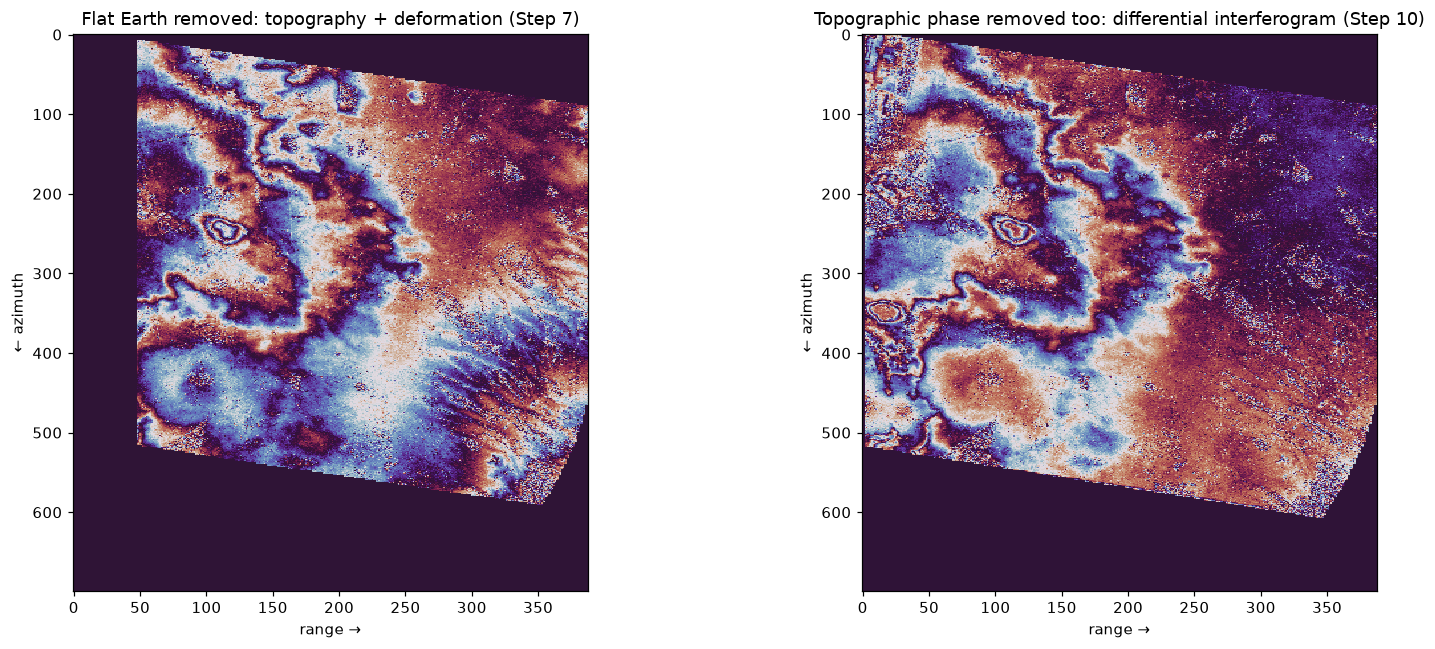

In [6]:
# Steps 7, 8 and 10 for the single pair (7 January → 13 April).
# The two bursts are still separate here; deburst joins them on the reference geometry.

anns_ref = members[REF]["ann"]
ids_ref = members[REF]["burst"]  # burst indices on the reference date


def deburst(layers):  # join the bursts of one layer into one image
    # Stitch the burst layers into one image, dropping the redundant overlap lines.
    # Every date uses the reference burst timing, because that is the grid they were resampled onto.
    return sar.deburst(list(layers), anns_ref[0], ids_ref, anns=anns_ref)


i, j = PAIR  # the two dates of the pair

# 1. The interferogram of each burst: reference times the conjugate of the secondary.
#    Its phase is flat-Earth + topography + deformation + atmosphere + noise.
raw = [slcs[i][k] * np.conj(slcs[j][k]) for k in range(len(BURSTS))]

# 2. Flat-Earth only (Step 7). flat_delta_range is the range difference to the ellipsoid.
#    The reference date has none stored, so its contribution is zero when i is REF.
flat_only = [raw[k] * np.exp(-1j * insar.flat_earth_phase(co["stack"][j]["flat_delta_range"][k] -
                                                           (0 if i == REF else co["stack"][i]["flat_delta_range"][k]), lam))
             for k in range(len(BURSTS))]

# 3. Differential interferogram (Step 10). topographic_phase inside this call uses the range
#    difference at the DEM surface, drange[j] - drange[i], so both the flat-Earth term and the
#    topographic term come out. What remains is deformation, atmosphere, residual orbit and noise.
diff = [insar.differential_interferogram(slcs[i][k], slcs[j][k], drange[j][k] - drange[i][k], lam) for k in range(len(BURSTS))]

# Powers of the two dates, kept so coherence can be estimated after multilooking.
p_i = [np.abs(x) ** 2 for x in slcs[i]]
p_j = [np.abs(x) ** 2 for x in slcs[j]]  # secondary intensity per burst

# 4. Step 8. Join the bursts. t_full is the zero-Doppler time of each debursted line.
#    G holds the same geometry (DEM height, slant range, incidence) on that grid.
ifg_flat, t_full = deburst(np.nan_to_num(f) for f in flat_only)
ifg_diff, _ = deburst(diff)  # the differential interferogram, debursted
# geometry layers, debursted
G = {k: deburst(co["geometry"][k])[0] for k in ("dem_height", "slant_range", "incidence")}
print(f"debursted: {ifg_diff.shape[0]} lines x {ifg_diff.shape[1]} samples")  # image size

# 5. Wrapped phase after a light multilook, so the fringes are visible. Left panel still contains
#    the topographic fringes; the right panel is the differential interferogram.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
# the two interferograms with their titles
for ax, z, t in [(axes[0], ifg_flat, "Flat Earth removed: topography + deformation (Step 7)"),
                 (axes[1], ifg_diff, "Topographic phase removed too: differential interferogram (Step 10)")]:
    # their phase after 4 x 16 looks
    ax.imshow(np.angle(insar.multilook_complex(z, (4, 16))), cmap="twilight", interpolation="none", aspect=0.6)
    ax.set(title=t, xlabel="range →", ylabel="← azimuth")  # title and axis labels
plt.tight_layout(); plt.show()  # arrange and draw

The single pair spans 96 days with a perpendicular baseline of about −37 m (precise orbits; ASF's stack lists −33 m), so its height of ambiguity is about 320 m. Even the hills in the AOI therefore produce only a few topographic fringes, and most fringes in both panels are deformation; removing the topographic phase changes the picture mainly over the hills. On this descending pass the radar looks west, so slant range increases westward: the old lake bed in the east is on the left of these radar-geometry images and the western hills on the right. The fringes concentrated on the left are the subsidence; each is 2.8 cm of line-of-sight motion.

### Multilook, Goldstein filter, unwrap

Multilooking by 2 azimuth × 8 range pixels gives about 28 m × 34 m on the ground. Coherence is
estimated from the multilooked products with a further 3 × 3 window. The Goldstein filter
(α = 0.6) sharpens the fringes, and SNAPHU unwraps them in **DEFO** cost mode, the statistical
model for deformation (smooth, with no layover-type jumps), as Step 13 recommends; pixels with
coherence below 0.25 are masked.


multilooked 1399 x 776; median coherence 0.57, 75% above 0.4; SNAPHU (DEFO) 32 s


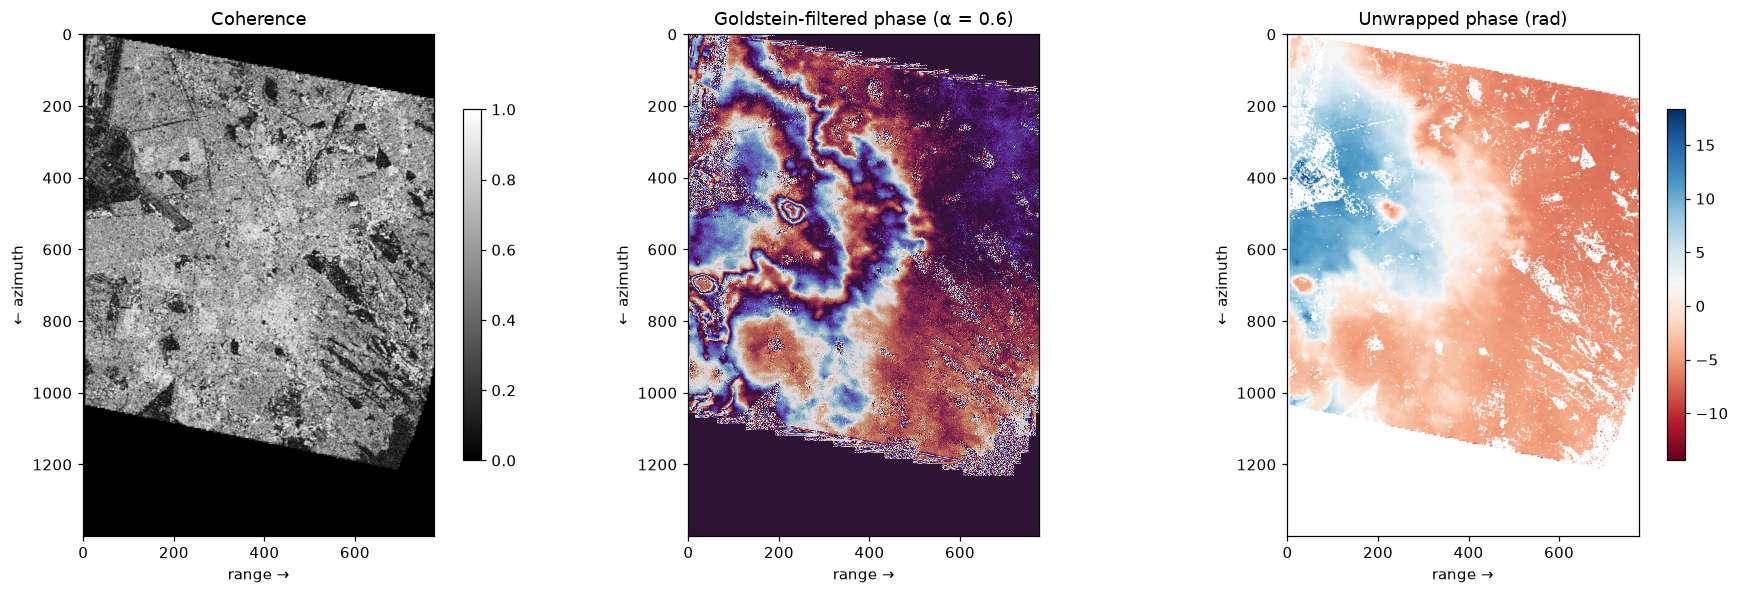

In [7]:
# Steps 11-13. Multilook the differential interferogram, estimate coherence, filter the phase
# with Goldstein, and unwrap it with SNAPHU in DEFO mode.

from scipy import ndimage


def box(x, size=3):  # 3 x 3 boxcar mean (complex inputs filtered part by part)
    # Moving average. A complex array is filtered in real and imaginary parts separately,
    # which is the spatial window inside the coherence estimator below.
    if np.iscomplexobj(x):
        # complex input: filter real and imaginary parts
        return ndimage.uniform_filter(x.real, size) + 1j * ndimage.uniform_filter(x.imag, size)
    return ndimage.uniform_filter(x, size)  # real input: filter directly


def ml(x):  # multilook with the notebook's looks
    # Step 11. LOOKS is (2, 8): two azimuth lines by eight range samples.
    # Complex data are averaged as complex numbers, so the phase is not destroyed.
    return insar.multilook_complex(x, LOOKS) if np.iscomplexobj(x) else sar.multilook(np.asarray(x, "float64"), LOOKS)


def coherence(z, p1, p2):  # coherence = |mean(z)| / sqrt(mean(p1) x mean(p2))
    # γ = |⟨s1 s2*⟩| / sqrt(⟨|s1|²⟩ ⟨|s2|²⟩), here over a further 3 x 3 window on the multilooked grids.
    # Pixels where either image or the interferogram is empty stay at zero and are marked invalid.
    valid = (np.abs(z) > 0) & (p1 > 0) & (p2 > 0)
    # clipped to [0, 1], 0 outside valid pixels
    return np.where(valid, np.clip(np.abs(box(z)) / np.sqrt(box(p1) * box(p2) + 1e-30), 0, 1), 0), valid


# 1. Multilook the differential interferogram and the two powers it was made from.
z = ml(ifg_diff)
pm, ps = ml(deburst(p_i)[0]), ml(deburst(p_j)[0])  # multilooked intensities of the two dates
coh, valid = coherence(z, pm, ps)  # coherence and the valid mask

# 2. Zero-Doppler time of each multilooked line: average the LOOKS[0] full-resolution times
#    that fell into it. Whole lines at the end that do not fill a look are dropped.
nt = (t_full.size // LOOKS[0]) * LOOKS[0]
# average the azimuth times of each group of looks
t_ml = t_full[:nt].astype("int64").reshape(-1, LOOKS[0]).mean(1).astype("datetime64[ns]")
Gm = {k: ml(v) for k, v in G.items()}  # multilooked geometry layers

# 3. Slant range of the first multilooked pixel, and the range spacing after 8 looks.
#    slant_range_time * c/2 is the near range of the full burst; col0 skips the samples that
#    were cropped away, and half a look puts the value at the centre of the averaged pixel.
near_range = float(a0["slant_range_time"] * sar.SPEED_OF_LIGHT / 2 + (members[REF]["col0"][0] + (LOOKS[1] - 1) / 2) * a0["range_pixel_spacing"])
dr = LOOKS[1] * a0["range_pixel_spacing"]  # range size of a multilooked pixel (m)

# 4. Step 12. Goldstein filter on the unit-magnitude phasor, so only the phase is smoothed.
#    alpha = 0.6 is milder than the usual 1.0, which keeps the tight subsidence fringes.
#    Invalid pixels are set to 0 and do not enter a patch.
ALPHA = 0.6
# Goldstein filter on the normalised phase
filt = insar.goldstein_filter(np.where(valid, z / (np.abs(z) + 1e-30), 0), alpha=ALPHA, patch=32, overlap=8)

# 5. Step 13. SNAPHU in DEFO cost mode: the statistical model for smooth deformation.
#    nlooks counts the 3 x 3 coherence window on top of the 2 x 8 multilook.
#    Pixels with γ <= 0.25 are masked and left for the unwrapper to bridge around.
t0 = time.time()
# SNAPHU unwrapping in deformation mode, only where coherence > 0.25
unw = insar.unwrap(filt, coh, method="snaphu", cost="defo", nlooks=9 * LOOKS[0] * LOOKS[1], mask=valid & (coh > 0.25))
# size and median coherence
print(f"multilooked {z.shape[0]} x {z.shape[1]}; median coherence {np.median(coh[valid]):.2f}, "
      f"{np.mean(coh[valid] > 0.4):.0%} above 0.4; SNAPHU (DEFO) {time.time() - t0:.0f} s")

# 6. Coherence, filtered wrapped phase, and the continuous phase SNAPHU returned.
#    aspect uses the ground-range spacing (slant spacing / sin θ) so the pixels look square.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
# pixel aspect ratio in ground units
asp = LOOKS[0] * a0["azimuth_pixel_spacing"] / (dr / np.sin(np.radians(np.nanmedian(Gm["incidence"]))))
im = axes[0].imshow(coh, cmap="gray", vmin=0, vmax=1, aspect=asp); axes[0].set_title("Coherence")  # coherence
plt.colorbar(im, ax=axes[0], shrink=0.7)  # colour bar
# filtered phase
axes[1].imshow(np.angle(filt), cmap="twilight", interpolation="none", aspect=asp); axes[1].set_title(f"Goldstein-filtered phase (α = {ALPHA})")
im = axes[2].imshow(unw, cmap="RdBu", aspect=asp); axes[2].set_title("Unwrapped phase (rad)")  # unwrapped phase
plt.colorbar(im, ax=axes[2], shrink=0.7)  # colour bar
for ax in axes:  # axis labels
    ax.set(xlabel="range →", ylabel="← azimuth")  # for every panel
plt.tight_layout(); plt.show()  # arrange and draw

### Phase to displacement, terrain correction and the reference point

`insar.phase_to_los` converts unwrapped phase to line-of-sight displacement,
d = −λ φ / 4π, positive toward the satellite (Step 14), and `sar.terrain_correct` moves it onto
a 30 m UTM grid (Step 16). Displacements are relative, so a **reference point** is needed.
`insar.select_reference_point` picks the most coherent 7 × 7 neighbourhood inside a mask; here the
mask is the volcanic hills of the western AOI (above 2,350 m), which stand on rock rather than
lake clay and are known to be stable. `insar.reference_to_point` then makes every value relative
to it.


In [8]:
# Steps 14 and 16. Turn the unwrapped phase into line-of-sight displacement, geocode it,
# and make every value relative to one stable point in the western hills.

# 1. A 30 m UTM grid covering the AOI. The ellipsoid DEM defines the grid; the geoid DEM is
#    resampled onto it (resampling=2 is bilinear) and is what the map contours use later.
to_utm = Transformer.from_crs(4326, UTM, always_xy=True)
x0, y0 = to_utm.transform(AOI[0], AOI[1])  # south-west AOI corner in UTM
x1, y1 = to_utm.transform(AOI[2], AOI[3])  # north-east AOI corner in UTM
# 30 m UTM grid over the AOI, from the DEM
grid = dem_ell.rio.reproject(UTM, resolution=30, resampling=2).sel(x=slice(x0, x1), y=slice(y1, y0))
dem_utm = dem_geoid.rio.reproject_match(grid, resampling=2)  # geoid heights on the same grid
orbit_ref = anns_ref[0]["orbit"]  # orbit of the reference date

# 2. Step 14. d_LOS = -λ φ / 4π, in metres, positive toward the satellite.
los = insar.phase_to_los(unw, lam)

# 3. Step 16. Range-Doppler terrain correction onto `grid`. t_ml, near_range and dr describe
#    the multilooked radar grid; the reference orbit and the DEM supply the geometry.
geo = sar.terrain_correct({"los": los, "coherence": coh}, t_ml, near_range, dr, orbit_ref, grid)

# 4. Where a reference point is allowed to fall: coherent (γ > 0.35), at least 10 pixels in from
#    the map edge, and above 2,350 m. That elevation is the volcanic rock of the western hills,
#    not the lake clay that is subsiding.
good = geo["coherence"].values > 0.35
inner = np.zeros_like(good)  # pixels away from the AOI edge
inner[10:-10, 10:-10] = True                       # keep the reference away from the map edge
# stable reference area: good pixels high on the surrounding hills
stable = good & (dem_utm.values > 2350) & inner

# 5. The most coherent 7 x 7 neighbourhood inside that mask, then subtract its displacement
#    so the map reads zero there. Everything else is motion relative to that neighbourhood.
REF_PT = insar.select_reference_point(geo["coherence"].values, mask=stable, window=7)
# displacement relative to the reference point (7 x 7 window)
los_map = insar.reference_to_point(geo["los"].where(good), REF_PT, window=7)
# the reference point in longitude and latitude
rlon, rlat = Transformer.from_crs(UTM, 4326, always_xy=True).transform(float(grid.x[REF_PT[1]]), float(grid.y[REF_PT[0]]))
print(f"reference point: row {REF_PT[0]}, col {REF_PT[1]} ({rlat:.4f} N, {rlon:.4f} E), "  # print it
      f"coherence {float(geo['coherence'][REF_PT]):.2f}, elevation {float(dem_utm[REF_PT]):.0f} m")

reference point: row 410, col 109 (19.3885 N, -99.2087 E), coherence 0.76, elevation 2368 m


### Corrections: orbital ramp and topography-correlated troposphere

A single interferogram still contains a residual planar ramp and a tropospheric delay that
correlates with elevation (the AOI rises from the lake bed to the western hills). Both are
fitted on **stable** pixels only, the western hills used for the reference point, and removed: a
plane in map coordinates plus a term proportional to elevation. Fitting on the sinking lake bed
would remove part of the signal itself.


removed: ramp -1.2 cm east-west and -0.9 cm north-south across the AOI, elevation term -1.98 cm per km; stable-pixel spread 0.2 → 0.1 cm


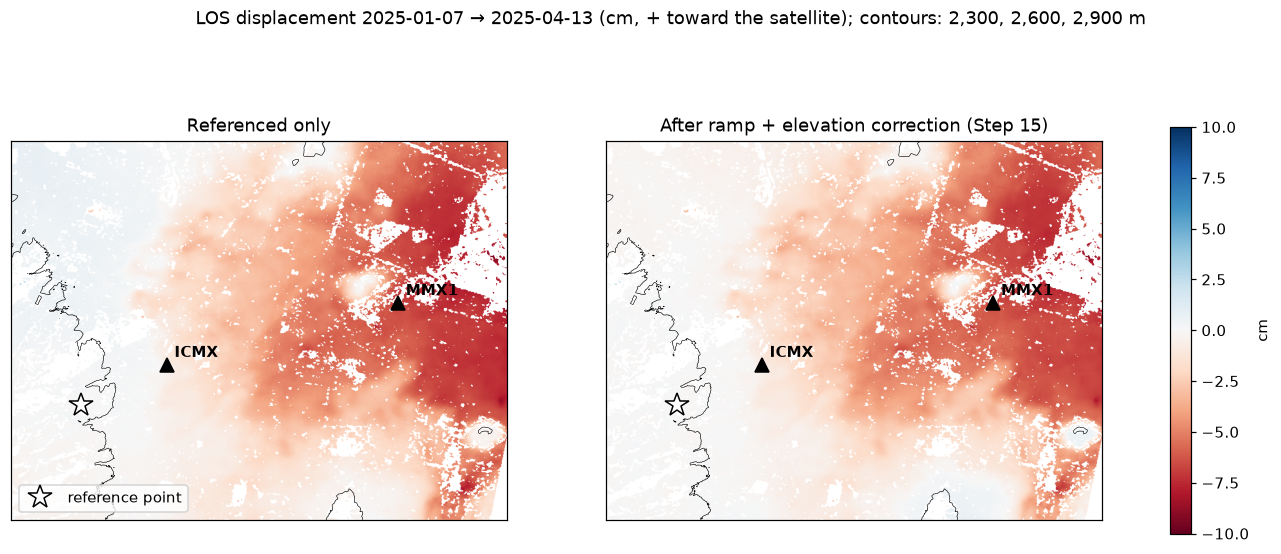

In [9]:
# Step 15. Fit a plane plus an elevation term on the stable hills only, and subtract it.
# Fitting on the lake bed would treat the subsidence itself as a ramp and remove part of it.

def fit_plane_elevation(field, mask, elevation):
    # Model: a + b (x / width) + c (y / height) + d (elevation in km).
    # b and c are then the east-west and north-south change across the whole map;
    # d is the delay per kilometre of elevation. Returns the corrected field and the four coefficients.
    yy, xx = np.mgrid[0:field.shape[0], 0:field.shape[1]]
    ok = mask & np.isfinite(field)  # pixels to fit
    # constant, east-west ramp, north-south ramp and elevation term
    terms = [np.ones_like(xx, float), xx / field.shape[1], yy / field.shape[0], elevation / 1000]
    A = np.stack([t[ok] for t in terms], 1)  # design matrix
    coef = np.linalg.lstsq(A, field[ok], rcond=None)[0]  # least-squares coefficients
    # field minus the fitted plane and elevation term
    return field - sum(c * t for c, t in zip(coef, terms)), coef


# 1. Remove the model, then re-zero the reference neighbourhood. Subtracting a plane moves
#    the reference point off zero, and the map should still read zero there.
los_corr, coef = fit_plane_elevation(los_map.values, stable, np.nan_to_num(dem_utm.values))
los_corr = insar.reference_to_point(los_corr, REF_PT, window=7)  # reference again after the correction
los_corr = grid.copy(data=los_corr.astype("float32"))  # back to a DataArray on the grid
# size of the removed ramps and elevation term
print(f"removed: ramp {coef[1] * 100:+.1f} cm east-west and {coef[2] * 100:+.1f} cm north-south across the AOI, "
      f"elevation term {coef[3] * 100:+.2f} cm per km; stable-pixel spread {np.nanstd(los_map.values[stable]) * 100:.1f} → "
      f"{np.nanstd(los_corr.values[stable]) * 100:.1f} cm")

# 2. Before and after, in centimetres. Contours are elevation; triangles are the GNSS stations;
#    the star is the reference point. The colour scale is symmetric, so red is motion toward
#    the satellite and blue is motion away from it (subsidence, on this descending track).
ext = [float(grid.x.min()), float(grid.x.max()), float(grid.y.min()), float(grid.y.max())]
st_xy = {s: to_utm.transform(*ll) for s, ll in STATIONS.items()}  # GNSS station positions in UTM
fig, axes = plt.subplots(1, 2, figsize=(16, 6))  # two panels
# before and after the correction
for ax, f, t in [(axes[0], los_map * 100, "Referenced only"), (axes[1], los_corr * 100, "After ramp + elevation correction (Step 15)")]:
    im = ax.imshow(f, cmap="RdBu", vmin=-10, vmax=10, extent=ext)  # displacement in cm
    # elevation contours
    ax.contour(dem_utm.x, dem_utm.y, dem_utm, levels=[2300, 2600, 2900], colors="k", linewidths=0.4)
    for s, (x, y) in st_xy.items():  # each GNSS station
        # a triangle and the station name
        ax.plot(x, y, "k^", ms=9); ax.annotate(s, (x, y), xytext=(5, 5), textcoords="offset points", fontweight="bold")
    # the reference point
    ax.plot(float(grid.x[REF_PT[1]]), float(grid.y[REF_PT[0]]), "w*", ms=16, mec="k", label="reference point")
    ax.set(title=t, xticks=[], yticks=[])  # title, no ticks
plt.colorbar(im, ax=axes, shrink=0.8, label="cm")  # colour bar
# overall title
fig.suptitle(f"LOS displacement {PAIR[0]} → {PAIR[1]} (cm, + toward the satellite); contours: 2,300, 2,600, 2,900 m")
axes[0].legend(loc="lower left")  # legend
plt.show()  # draw

The multilooked interferogram is 1,399 × 776 pixels. Its median coherence is 0.57, and 75 % of pixels exceed 0.4, typical of a city over three months. SNAPHU's DEFO mode unwraps it in about 30 s.

The reference point falls in the western hills at 2,368 m (19.389° N, 99.209° W), with a local coherence of 0.76. The corrections in Step 15 are small for this dry-season pair: ramps of about 1 cm across the AOI and an elevation term of −2 cm per km, which brings the spread of the stable hill pixels from 0.2 to 0.1 cm.

The map shows the classic Mexico City pattern. The hills in the west hardly move, and the motion away from the satellite increases eastward over the lake-bed clays, to more than 7 cm in 96 days in the east. Some incoherent patches (no data) remain.

### Quality control against GNSS

The Nevada Geodetic Laboratory publishes daily positions of both stations. Their east, north and
up motion between the two acquisition dates is projected onto the line of sight with
`sar.los_unit_vector` (the exact ground-to-satellite direction at each station, from the precise
orbit) and `insar.enu_to_los`. The InSAR reference point is not at a GNSS station, so the
comparison uses the **difference between the stations** (MMX1 − ICMX), which cancels any
reference offset in both data sets.


In [10]:
# Step 17. Project the GNSS east/north/up series onto the radar line of sight and compare
# it with the interferogram. The reference point is not at a station, so the comparison that
# does not depend on it is the difference between the two stations (MMX1 − ICMX).

def read_ngl(station):
    # Nevada Geodetic Laboratory tenv3 file: daily IGS20 positions. The east, north and up
    # columns are a reference coordinate plus a small offset, both in metres.
    path = CACHE / f"{station}.tenv3"
    if not path.exists():  # download the station file once
        # Nevada Geodetic Laboratory daily positions (IGS20)
        urllib.request.urlretrieve(f"https://geodesy.unr.edu/gps_timeseries/IGS20/tenv3/IGS20/{station}.tenv3", path)
    df = pd.read_csv(path, sep=r"\s+")  # whitespace-separated table
    t = pd.to_datetime(df["YYMMMDD"], format="%y%b%d")  # dates such as 25JAN07
    # east, north and up positions in metres
    return pd.DataFrame({"east": (df["_e0(m)"] + df["__east(m)"]).to_numpy(),
                         "north": (df["____n0(m)"] + df["_north(m)"]).to_numpy(),
                         "up": (df["u0(m)"] + df["____up(m)"]).to_numpy()}, index=t.to_numpy())


GWIN = ("2024-06-01", "2026-01-31")               # GNSS window around the 2025 InSAR dates
gnss = {s: read_ngl(s) for s in STATIONS}  # the time series of every station

# Ground-to-satellite unit vector at each station, from the precise orbit and the station height.
# Order is (east, north, up). On this descending track the up component is the largest.
los_vec = {s: sar.los_unit_vector(ll[1], ll[0], float(dem_ell.sel(x=ll[0], y=ll[1], method="nearest")), orbit_ref)
           for s, ll in STATIONS.items()}


def gnss_los_series(station):  # GNSS motion projected onto the radar line of sight
    # Daily positions dotted with the LOS unit vector: the motion the radar would have measured.
    g = gnss[station].loc[GWIN[0]:GWIN[1]]
    # east, north, up -> LOS with the station's LOS unit vector
    return pd.Series(insar.enu_to_los(g.east, g.north, g.up, los_vec[station]), index=g.index)


def gnss_fit(station, component="los"):  # linear rate of a station and the fitted line
    # Straight line through the daily series, in metres per year, and a function that evaluates it.
    # MMX1 has a long gap in 2025, so the rate fitted across the gap is what that station can offer.
    s_ = gnss_los_series(station) if component == "los" else gnss[station].loc[GWIN[0]:GWIN[1], component]
    ty = (s_.index - pd.Timestamp(DATES[0])).days / 365.25  # time in years since the first date
    rate, icpt = np.polyfit(ty, s_.values, 1)  # straight-line fit
    # the rate and a function that evaluates the line
    return rate, lambda d: icpt + rate * (pd.Timestamp(d) - pd.Timestamp(DATES[0])).days / 365.25


def gnss_change(station, d0, d1, days=3):  # GNSS change between two dates
    # LOS change between two dates. Prefer the mean of the daily positions within `days` of each
    # date; if either date has none (the MMX1 gap), fall back to the fitted rate times the interval.
    s_ = gnss_los_series(station)
    # positions within a few days of a date
    near = lambda d: s_[(s_.index >= pd.Timestamp(d) - pd.Timedelta(days=days)) & (s_.index <= pd.Timestamp(d) + pd.Timedelta(days=days))]
    a_, b_ = near(d0), near(d1)  # near the start and the end
    if len(a_) and len(b_):  # if both are available
        return b_.mean() - a_.mean(), "daily positions"  # use the daily positions
    # otherwise use the fitted rate
    return gnss_fit(station)[0] * (pd.Timestamp(d1) - pd.Timestamp(d0)).days / 365.25, "fitted rate x interval"


def insar_at(field, station, r=2):  # InSAR value at a station: median of a small window
    # Median of a 5 x 5 pixel window around the station, so one noisy pixel does not decide the value.
    x, y = st_xy[station]
    # grid column and row closest to the station
    ix, iy = int(np.argmin(np.abs(grid.x.values - x))), int(np.argmin(np.abs(grid.y.values - y)))
    # median of the (2r + 1) x (2r + 1) window
    return float(np.nanmedian(np.asarray(field)[..., iy - r:iy + r + 1, ix - r:ix + r + 1]))


# One row per station: the LOS vector, how many GNSS days exist in 2025, and the two LOS changes.
rows = {}
for s in STATIONS:  # every station
    v = los_vec[s]  # its LOS unit vector
    change, how = gnss_change(s, *PAIR)  # GNSS LOS change over the pair
    # days with GNSS data in 2025
    days25 = int(((gnss[s].index >= "2025-01-01") & (gnss[s].index <= "2025-12-31")).sum())
    # one row of the comparison
    rows[s] = {"LOS vector (e, n, u)": f"({v[0]:+.2f}, {v[1]:+.2f}, {v[2]:+.2f})", "GNSS days in 2025": days25,
               "GNSS LOS change (cm)": round(100 * change, 2), "GNSS from": how,
               "InSAR LOS change (cm)": round(100 * insar_at(los_corr, s), 2)}
qc = pd.DataFrame(rows).T  # as a table

# Station difference. Any constant added by the choice of reference point cancels in both columns.
dg = qc.loc["MMX1", "GNSS LOS change (cm)"] - qc.loc["ICMX", "GNSS LOS change (cm)"]
# MMX1 relative to ICMX in InSAR
di = qc.loc["MMX1", "InSAR LOS change (cm)"] - qc.loc["ICMX", "InSAR LOS change (cm)"]
# relative motion: GNSS vs InSAR
print(f"MMX1 − ICMX over {PAIR[0]} → {PAIR[1]}: GNSS {dg:.1f} cm, InSAR {di:.1f} cm (difference {di - dg:+.1f} cm)")
qc  # show the table

MMX1 − ICMX over 2025-01-07 → 2025-04-13: GNSS -5.9 cm, InSAR -6.0 cm (difference -0.1 cm)


,"LOS vector (e, n, u)",GNSS days in 2025,GNSS LOS change (cm),GNSS from,InSAR LOS change (cm)
MMX1,"(+0.51, -0.10, +0.85)",90,-6.77,fitted rate x interval,-6.87
ICMX,"(+0.52, -0.10, +0.85)",323,-0.82,daily positions,-0.84


The line-of-sight vector at both stations is (0.51, −0.10, 0.85): the descending, west-looking radar sees vertical motion at 85 % and east-west motion at 51 %. Over 7 January → 13 April 2025:

| | GNSS | InSAR |
|---|---|---|
| ICMX (daily positions) | −0.82 cm | −0.84 cm |
| MMX1 (fitted rate × 96 days) | −6.77 cm | −6.87 cm |
| MMX1 − ICMX | −5.9 cm | −6.0 cm |

A single differential interferogram agrees with GNSS to about 1 mm here. MMX1 has a data gap from October 2024 to September 2025, so its value is the linear trend fitted to the daily positions on either side of the gap (June 2024 to January 2026), times the 96-day interval. Mexico City subsidence is steady enough for that to be a fair comparison.

### Multi-temporal InSAR: an SBAS time series for 2025

A single interferogram measures one interval and carries one atmosphere. The small-baseline
subset approach forms many short interferograms between the 12 dates (each date with its next
two neighbours: 21 pairs, the blue network in Step 1) from the already co-registered stack,
unwraps each, and inverts the network for the displacement at every date
(`insar.sbas_inversion`, Berardino et al. 2002). Each interferogram is referenced to the same
point and corrected for ramp and elevation-correlated delay before the inversion; the
atmosphere of each date then averages down in the fitted velocity (`insar.velocity`).


In [11]:
# The SBAS network. Each of the 21 pairs is formed from the stack that is already co-registered,
# unwrapped, referenced and corrected exactly as the single pair was, then inverted for the
# displacement at every date (Berardino et al. 2002).

# Multilooked power of every date, the denominator of the coherence of any pair.
p_all = {d: deburst([np.abs(x) ** 2 for x in slcs[d]])[0] for d in DATES}
p_ml = {d: ml(v) for d, v in p_all.items()}  # multilooked intensity of every date


def network_ifg(i, j):  # one network interferogram, processed like the single pair
    # Steps 7-16 for one pair. Returns the corrected LOS displacement (metres) and the coherence,
    # both on the 30 m map grid and both relative to the same reference point.
    d = [insar.differential_interferogram(slcs[i][k], slcs[j][k], drange[j][k] - drange[i][k], lam) for k in range(len(BURSTS))]
    zz = ml(deburst(d)[0])  # multilooked interferogram
    c, v = coherence(zz, p_ml[i], p_ml[j])  # coherence
    # Goldstein filter
    f = insar.goldstein_filter(np.where(v, zz / (np.abs(zz) + 1e-30), 0), alpha=ALPHA, patch=32, overlap=8)
    # SNAPHU unwrapping
    u = insar.unwrap(f, c, method="snaphu", cost="defo", nlooks=9 * LOOKS[0] * LOOKS[1], mask=v & (c > 0.25))
    # LOS displacement, terrain-corrected to the UTM grid
    g = sar.terrain_correct({"los": insar.phase_to_los(u, lam), "coherence": c}, t_ml, near_range, dr, orbit_ref, grid)
    ok = g["coherence"].values > 0.3  # coherent pixels
    # reference to the reference point
    ref_los = insar.reference_to_point(g["los"].where(ok), REF_PT, window=7).values
    # remove ramp and elevation term
    corr, _ = fit_plane_elevation(ref_los, stable & ok, np.nan_to_num(dem_utm.values))
    # referenced displacement and coherence
    return insar.reference_to_point(corr, REF_PT, window=7), g["coherence"].values


# 1. Build the 21 interferograms. The blue network in Step 1 is exactly this list of pairs.
t0 = time.time()
ifgs, cohs = [], []  # results of all pairs
for a, b in NETWORK:  # every pair of the network
    l_, c_ = network_ifg(a, b)  # process it
    ifgs.append(l_); cohs.append(c_)  # keep displacement and coherence
# run time and coherence per pair
print(f"{len(NETWORK)} interferograms in {time.time() - t0:.0f} s; median coherence per pair "
      f"{np.nanmedian([np.nanmedian(c) for c in cohs]):.2f} (range {np.nanmin([np.nanmedian(c) for c in cohs]):.2f}-"
      f"{np.nanmax([np.nanmedian(c) for c in cohs]):.2f})")

# 2. Keep a pixel only where at least 80 % of the interferograms are coherent (γ > 0.3).
#    sbas_inversion solves the network for the displacement at each date, in metres.
#    velocity fits a line through that series; multiplying by 100 reports it in cm/yr.
ifg_stack = xr.DataArray(np.stack(ifgs), dims=("pair", "y", "x"), coords={"y": grid.y, "x": grid.x})
reliable = (np.stack(cohs) > 0.3).mean(0) >= 0.8  # pixels coherent in at least 80 % of the interferograms
# SBAS inversion: displacement at every date
ts = insar.sbas_inversion(ifg_stack.where(reliable), NETWORK).assign_attrs(units="m")
vel = insar.velocity(ts * 100)            # cm per year
v_map = vel["velocity"].where(reliable)  # velocity of the reliable pixels

# 3. Loop closure. For every trio of dates the two short pairs should sum to the long pair:
#    (i → i+1) + (i+1 → i+2) − (i → i+2). A residual of a few millimetres means the unwrapping agrees.
closure = []
for k in range(len(DATES) - 2):  # each triplet of consecutive dates
    # indices of the three interferograms of the loop
    i1, i2, i3 = NETWORK.index((DATES[k], DATES[k + 1])), NETWORK.index((DATES[k + 1], DATES[k + 2])), NETWORK.index((DATES[k], DATES[k + 2]))
    # loop closure: phase(1-2) + phase(2-3) - phase(1-3) should be zero
    closure.append(np.nanmedian(np.abs(ifgs[i1] + ifgs[i2] - ifgs[i3])[reliable]) * 1000)
# reliable share and median closure
print(f"reliable pixels: {reliable[np.isfinite(grid.values)].mean():.0%} of the AOI; median |loop closure| {np.median(closure):.1f} mm")

21 interferograms in 652 s; median coherence per pair 0.65 (range 0.60-0.71)


reliable pixels: 86% of the AOI; median |loop closure| 1.3 mm


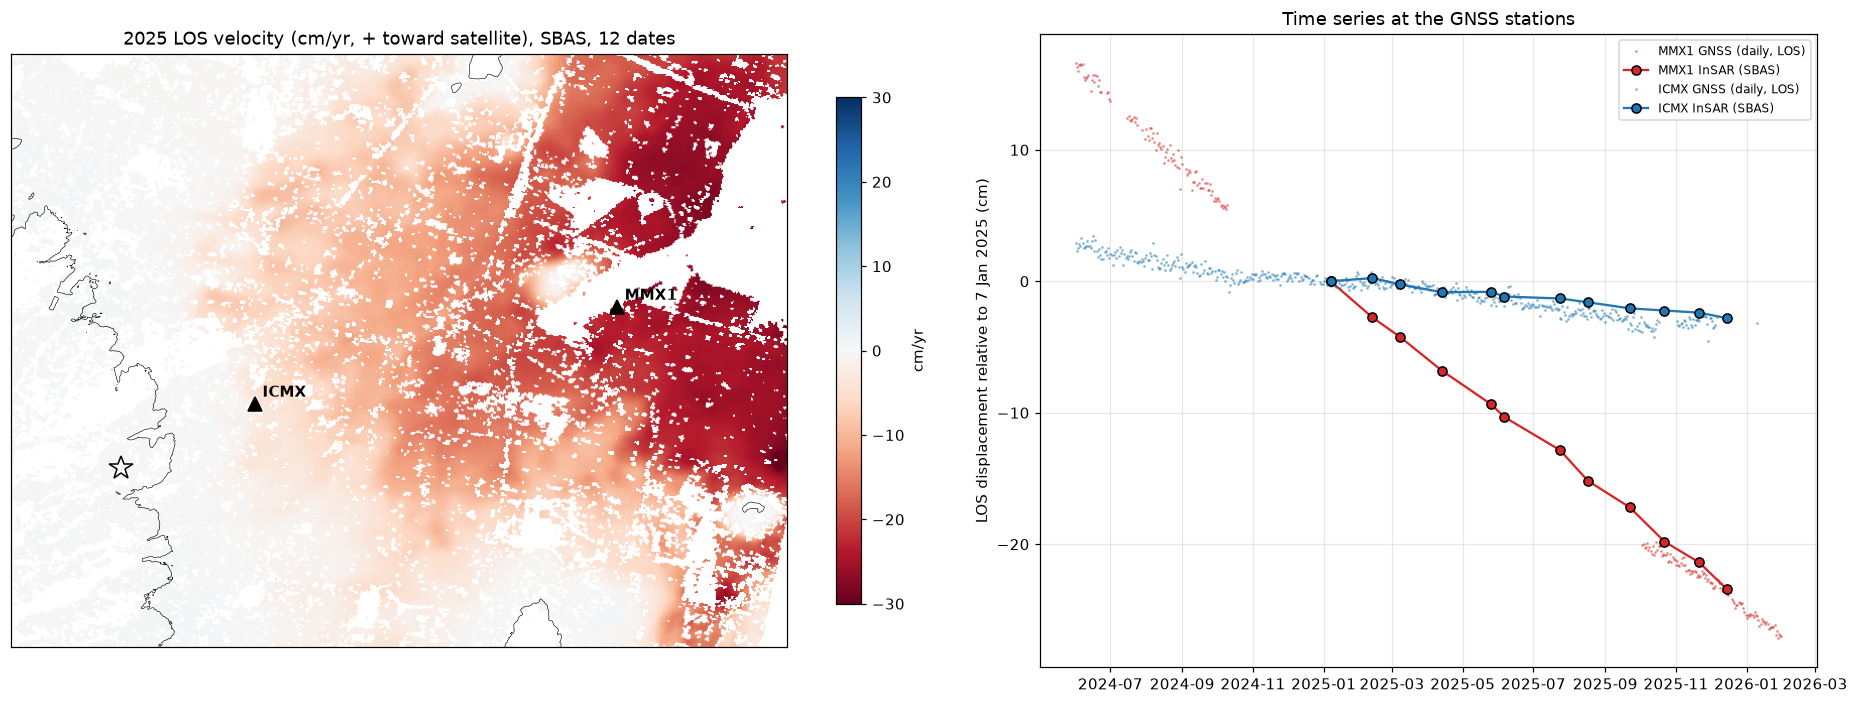

,GNSS LOS rate (cm/yr),InSAR LOS rate (cm/yr),GNSS vertical rate (cm/yr),GNSS east rate (cm/yr)
MMX1,-25.7,-24.6,-30.1,-0.1
ICMX,-3.8,-3.1,-4.6,0.2
MMX1 − ICMX,-21.9,-21.5,-25.5,-0.4


In [12]:
# Velocity map and the time series at the two stations, then the rates side by side.

# 1. LOS velocity, cm/yr, positive toward the satellite. Same symbols as the single-pair map:
#    elevation contours, GNSS triangles, and the reference point as a star.
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
im = axes[0].imshow(v_map, cmap="RdBu", vmin=-30, vmax=30, extent=ext)  # velocity map
# elevation contours
axes[0].contour(dem_utm.x, dem_utm.y, dem_utm, levels=[2300, 2600, 2900], colors="k", linewidths=0.4)
for s, (x, y) in st_xy.items():  # each station
    # a triangle and the name
    axes[0].plot(x, y, "k^", ms=9); axes[0].annotate(s, (x, y), xytext=(5, 5), textcoords="offset points", fontweight="bold")
axes[0].plot(float(grid.x[REF_PT[1]]), float(grid.y[REF_PT[0]]), "w*", ms=16, mec="k")  # the reference point
# title, no ticks
axes[0].set(title="2025 LOS velocity (cm/yr, + toward satellite), SBAS, 12 dates", xticks=[], yticks=[])
plt.colorbar(im, ax=axes[0], shrink=0.8, label="cm/yr")  # colour bar

# 2. At each station, the daily GNSS series projected onto the LOS (dots) and the 12 InSAR dates
#    (line). Both are shifted to zero on 7 January, so the slopes can be compared directly.
for s, c in zip(STATIONS, ["tab:red", "tab:blue"]):
    g_los = gnss_los_series(s)  # GNSS series in LOS
    _, line = gnss_fit(s)  # its fitted line
    # daily GNSS positions
    axes[1].plot(g_los.index, 100 * (g_los - line(DATES[0])), ".", ms=2, color=c, alpha=0.35, label=f"{s} GNSS (daily, LOS)")
    ins = np.array([insar_at(ts.sel(time=t), s) for t in ts.time.values])  # InSAR time series at the station
    # InSAR points
    axes[1].plot(pd.to_datetime(ts.time.values), 100 * (ins - ins[0]), "o-", color=c, mec="k", label=f"{s} InSAR (SBAS)")
# labels and title
axes[1].set(ylabel="LOS displacement relative to 7 Jan 2025 (cm)", title="Time series at the GNSS stations")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)  # legend and grid
plt.tight_layout(); plt.show()  # arrange and draw

# 3. Rates. The InSAR rate is a line through the 12 dates at the station. The GNSS rates are the
#    same fit as in Step 17, for the LOS and for the vertical and east components separately.
#    The last row is the difference between the stations, which does not depend on the reference point.
rows = {}
for s in STATIONS:  # each station
    ins = np.array([insar_at(ts.sel(time=t), s) for t in ts.time.values])  # InSAR time series at the station
    t_y = (pd.to_datetime(ts.time.values) - pd.Timestamp(DATES[0])).days / 365.25  # time in years
    # GNSS and InSAR rates
    rows[s] = {"GNSS LOS rate (cm/yr)": 100 * gnss_fit(s)[0], "InSAR LOS rate (cm/yr)": 100 * np.polyfit(t_y, ins, 1)[0],
               "GNSS vertical rate (cm/yr)": 100 * gnss_fit(s, "up")[0], "GNSS east rate (cm/yr)": 100 * gnss_fit(s, "east")[0]}
rates = pd.DataFrame(rows).T  # as a table
rates.loc["MMX1 − ICMX"] = rates.loc["MMX1"] - rates.loc["ICMX"]  # relative rate between the two stations
rates.round(1)  # show the table

The 21 interferograms take about 10.5 minutes (co-registration was already done once for all dates). Their median coherence ranges from 0.60 to 0.71. The inversion uses the 86 % of the AOI that is coherent in at least 80 % of the interferograms. The network is consistent: the median loop closure, the mismatch of (i→i+1) + (i+1→i+2) − (i→i+2), is 1.3 mm.

| | GNSS LOS rate | InSAR LOS rate | GNSS vertical rate |
|---|---|---|---|
| MMX1 | −25.7 cm/yr | −24.6 cm/yr | −30.1 cm/yr |
| ICMX | −3.8 cm/yr | −3.1 cm/yr | −4.6 cm/yr |
| MMX1 − ICMX | −21.9 cm/yr | −21.5 cm/yr | −25.5 cm/yr |

The InSAR rates agree with GNSS to within about 1 cm/yr at both stations, and to 0.4 cm/yr for the difference between them. Both stations move less than 0.3 cm/yr east-west, so the line-of-sight signal is almost all vertical. In the time-series panel, the 12 InSAR dates at MMX1 bridge the station's 11-month data gap and land on the GNSS trend on both sides.


In [13]:
# Write the maps. Dividing the LOS velocity by cos(incidence) converts it to a vertical rate
# only if the motion really is vertical: the up-component of the line-of-sight vector is cos θ,
# and any east-west motion is then folded into that number. The GNSS east rates above are
# smaller than 0.3 cm/yr, which is why the assumption is reasonable here.
up_equiv = v_map / np.cos(np.radians(sar.terrain_correct(Gm["incidence"], t_ml, near_range, dr, orbit_ref, grid).values))
# save the vertical-equivalent velocity
up_equiv.rio.write_crs(UTM).rio.write_nodata(np.nan).rio.to_raster(OUT / "mexico_city_2025_vertical_velocity_cm_per_yr.tif")
# save the LOS velocity
v_map.rio.write_crs(UTM).rio.write_nodata(np.nan).rio.to_raster(OUT / "mexico_city_2025_los_velocity_cm_per_yr.tif")
# save the displacement time series
ts.where(reliable).rio.write_crs(UTM).to_netcdf(OUT / "mexico_city_2025_los_timeseries.nc")

fast = up_equiv.values[np.isfinite(up_equiv.values)]  # valid values
# the fastest subsidence rates
print(f"vertical-equivalent velocity (assuming purely vertical motion): 1st percentile {np.percentile(fast, 1):.1f} cm/yr, "
      f"median {np.median(fast):.1f} cm/yr; {np.mean(fast < -10):.0%} of reliable pixels sink faster than 10 cm/yr")
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")  # list the saved files

vertical-equivalent velocity (assuming purely vertical motion): 1st percentile -31.2 cm/yr, median -7.3 cm/yr; 42% of reliable pixels sink faster than 10 cm/yr
saved:
  mexico_city_2025_los_timeseries.nc
  mexico_city_2025_los_velocity_cm_per_yr.tif
  mexico_city_2025_vertical_velocity_cm_per_yr.tif


## Summary, exercises and references

- **Data and processing.** 12 Sentinel-1 IW SLC dates of 2025 (descending track 41, two bursts each) were co-registered to one reference with DEM-assisted back-geocoding and ESD (`sar.coregister_stack`). ESD exposed a systematic azimuth offset of about 0.17 m between Sentinel-1A and Sentinel-1C acquisitions.
- **One interferogram (Steps 7 to 17).** The 7 January → 13 April pair, after topographic phase removal, unwrapping, referencing to the stable western hills and correction, matches GNSS to about 1 mm: −6.0 cm (InSAR) against −5.9 cm (GNSS) between MMX1 and ICMX.
- **Time series.** A 21-interferogram SBAS network (loop closure 1.3 mm) gives LOS velocities of −24.6 cm/yr at MMX1 and −3.1 cm/yr at ICMX, against −25.7 and −3.8 cm/yr from GNSS.
- **The city.** Assuming the motion is vertical, the fastest 1 % of reliable pixels sink by 31 cm/yr or more, the median pixel by 7 cm/yr, and 42 % of the reliable area by more than 10 cm/yr. The velocity map and the time series are saved as GeoTIFF and NetCDF in `outputs/dinsar_mexico_city/`.

The main limits are the usual ones: coherence (open and vegetated ground drops out), the single look direction (LOS only; a second track would separate vertical and east-west motion), and atmosphere, which the SBAS network averages down but does not remove.

### Exercises

1. Replace the reference point with ICMX (a GNSS station) and repeat Step 17. What changes, and why
   does the station difference not change?
2. Process the 13 April → 25 May pair with `insar.unwrap(..., cost="smooth")` instead of DEFO, and
   compare the unwrapped field in the fastest-sinking area.
3. Skip Step 15. How large is the elevation-correlated delay in one rainy-season pair (e.g.
   24 July → 17 August) compared with a dry-season pair?
4. Add the ascending track 5 (bursts 005_008704_IW1) for the same dates and use
   `insar.decompose_asc_desc` to separate vertical from east-west motion.
5. Extend the network to each date's next three neighbours. Does the loop closure improve?

### References

- Berardino, P., Fornaro, G., Lanari, R., & Sansosti, E. (2002). A new algorithm for surface deformation monitoring
  based on small baseline differential SAR interferograms. *IEEE TGRS*, 40(11), 2375 to 2383.
- Chaussard, E., Wdowinski, S., Cabral-Cano, E., & Amelung, F. (2014). Land subsidence in central Mexico detected by
  ALOS InSAR time-series. *Remote Sensing of Environment*, 140, 94 to 106.
- Chen, C. W., & Zebker, H. A. (2001). Two-dimensional phase unwrapping with use of statistical models for cost
  functions in nonlinear optimization. *JOSA A*, 18(2), 338 to 351.
- Yagüe-Martínez, N., et al. (2016). Interferometric processing of Sentinel-1 TOPS data. *IEEE TGRS*, 54(4), 2220-2234.
- Blewitt, G., Hammond, W. C., & Kreemer, C. (2018). Harnessing the GPS data explosion for interdisciplinary
  science. *Eos*, 99.
